# Optimisation of the SDO thresholds (PIC sweep)

The results of `PIC/sweep.dag` (one set per line of `parameters.txt`): every set has its light curve, RV, FWHM, BIS, contrast and CCF time series (`sets/<set>/`, `opt_rv/`) and its MAD / RMS against HARPS-N, SORCE/TIM and TSIS-1 (`sets/<set>/stats.json`, all in `results/sweep_stats.csv`). This notebook reads the folder of the sets (copied from PIC; path `sweep_results` of `local_paths.ini`), recomputes the statistics if needed (e.g. on another window) and makes the figures of the optimisation: heatmaps of I_th × B_sat per T_sp and I_th × T_sp per B_sat, and the RMS against every parameter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sunsim import observations as obs, local_path

BASE = '/data/spotless/scratch/sstucki/starsim/dumusque_mu/sets_fraction_size_4096_N60' #local_path('sweep_results_fraction')               # the folder 'sets' of the sweep (or its parent)
START = '2015-07-18'                             # t = 0 of the simulations
WINDOW = None                                    # e.g. ('2021-01-01', '2024-01-01'): statistics on these epochs only
RECOMPUTE = WINDOW is not None                   # recompute stats.json of every set (the observations are needed)

In [2]:
if RECOMPUTE:
    import glob, json, os
    harps = obs.load_harpsn(local_path('harpsn_sun'), START)
    sorce, tsis = obs.load_sorce(local_path('sorce_tsi'), START), obs.load_tsis(local_path('tsis_tsi'), START)
    cuts = obs.load_interventions(local_path('harpsn_interventions'), START)
    for f in sorted(glob.glob(os.path.join(str(BASE), '**', 'stats.json'), recursive=True)):
        params = {k: v for k, v in json.load(open(f)).items() if k in ('noise_th', 'I_th', 'B_sat', 'T_sp')}
        obs.sweep_stats(os.path.dirname(f), START, harps, sorce, tsis, cuts, window=WINDOW, params=params)

df = obs.load_sweep_stats(BASE)
print(len(df), 'sets')
for value, unit in (('rv_rms', 'm/s'), ('rv_mad', 'm/s'), ('sorce_rms', 'ppm'), ('tsis_rms', 'ppm')):
    if value in df and df[value].notna().any():
        b = obs.best_sets(df, value, 1).iloc[0]
        print('best %-9s %.4g %s: T_sp = %g, noise_th = %g, I_th = %g, B_sat = %g (range %.4g -> %.4g)'
              % (value, b[value], unit, b['T_sp'], b['noise_th'], b['I_th'], b['B_sat'], df[value].min(), df[value].max()))
obs.best_sets(df, 'rv_rms', 10)[['T_sp', 'noise_th', 'I_th', 'B_sat', 'rv_rms', 'rv_mad', 'sorce_rms', 'tsis_rms']]

84 sets
best rv_rms    0.8463 m/s: T_sp = 1100, noise_th = 8, I_th = 0.8, B_sat = 20 (range 0.8463 -> 1.062)
best rv_mad    0.5416 m/s: T_sp = 300, noise_th = 8, I_th = 0.9, B_sat = 8 (range 0.5416 -> 0.5852)
best sorce_rms 168.2 ppm: T_sp = 600, noise_th = 8, I_th = 0.7, B_sat = 10 (range 168.2 -> 611)
best tsis_rms  136.7 ppm: T_sp = 600, noise_th = 8, I_th = 0.75, B_sat = 10 (range 136.7 -> 1320)


,T_sp,noise_th,I_th,B_sat,rv_rms,rv_mad,sorce_rms,tsis_rms
30,1100.0,8.0,0.8,20.0,0.846264,0.543242,230.833577,253.171942
24,1100.0,8.0,0.8,10.0,0.846264,0.543242,230.833577,253.171942
27,1100.0,8.0,0.8,15.0,0.846264,0.543242,230.833577,253.171942
33,1100.0,8.0,0.8,8.0,0.846264,0.543242,230.833577,253.171942
29,600.0,8.0,0.8,15.0,0.846536,0.543030,182.789994,152.880063
26,600.0,8.0,0.8,10.0,0.846536,0.543030,182.789994,152.880063
32,600.0,8.0,0.8,20.0,0.846536,0.543030,182.789994,152.880063
35,600.0,8.0,0.8,8.0,0.846536,0.543030,182.789994,152.880063
34,300.0,8.0,0.8,8.0,0.846686,0.543089,168.691500,143.931519
28,300.0,8.0,0.8,15.0,0.846686,0.543089,168.691500,143.931519


## RV against HARPS-N

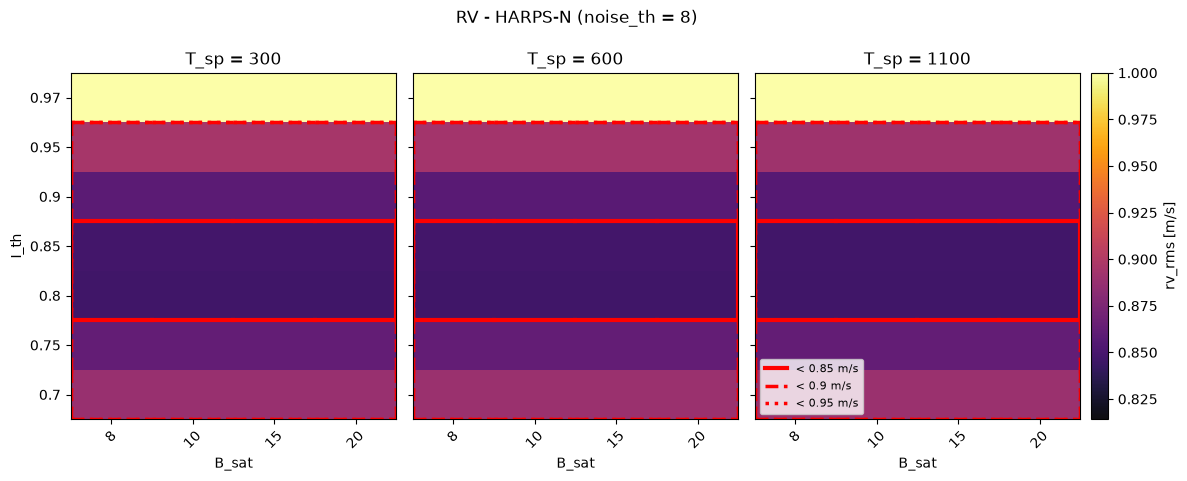

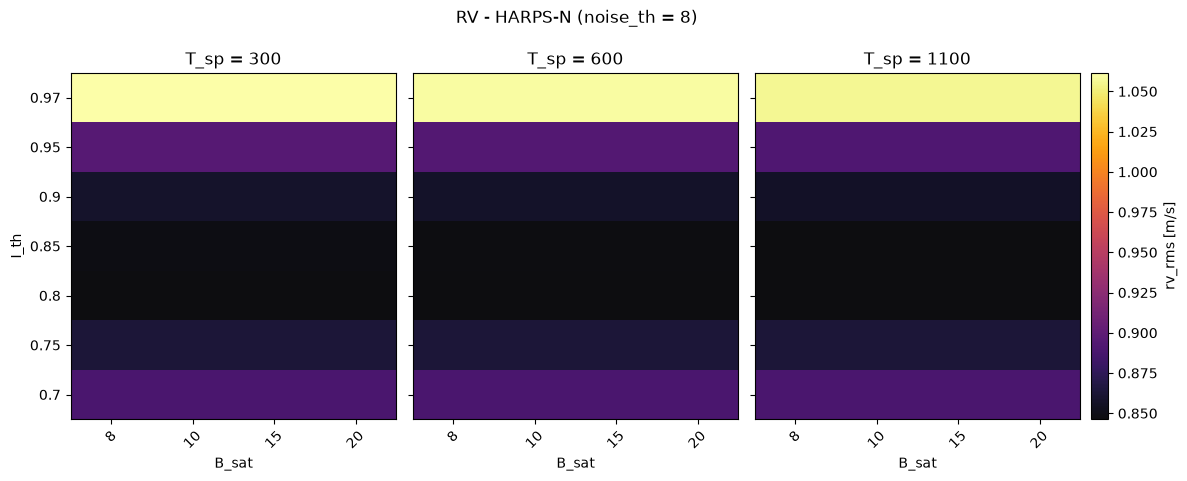

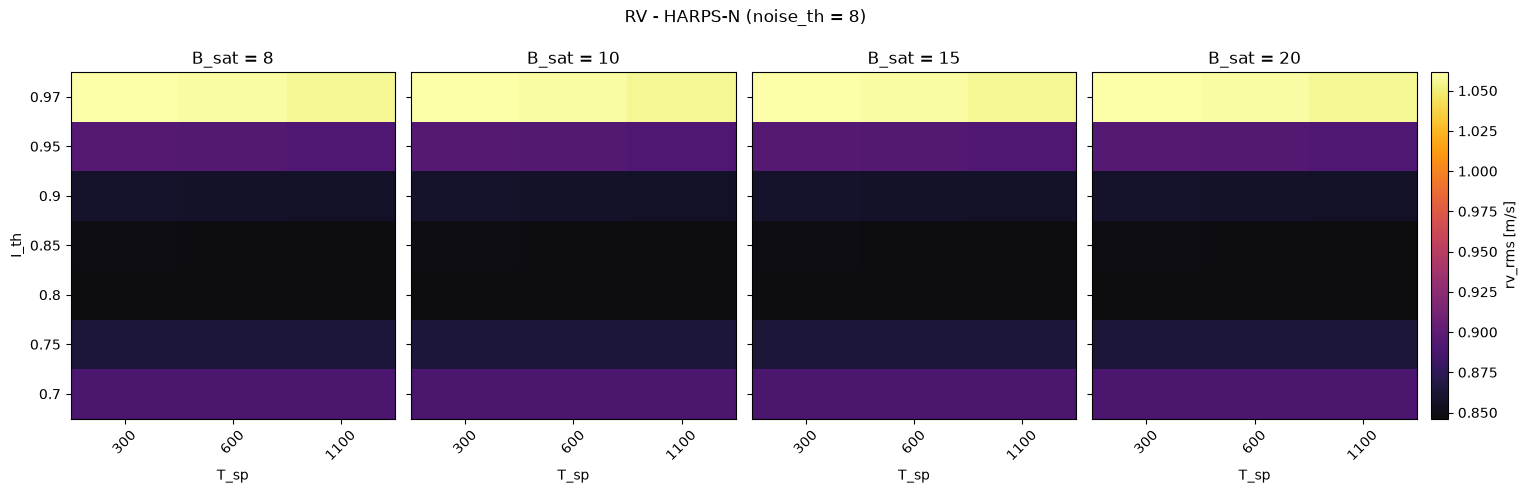

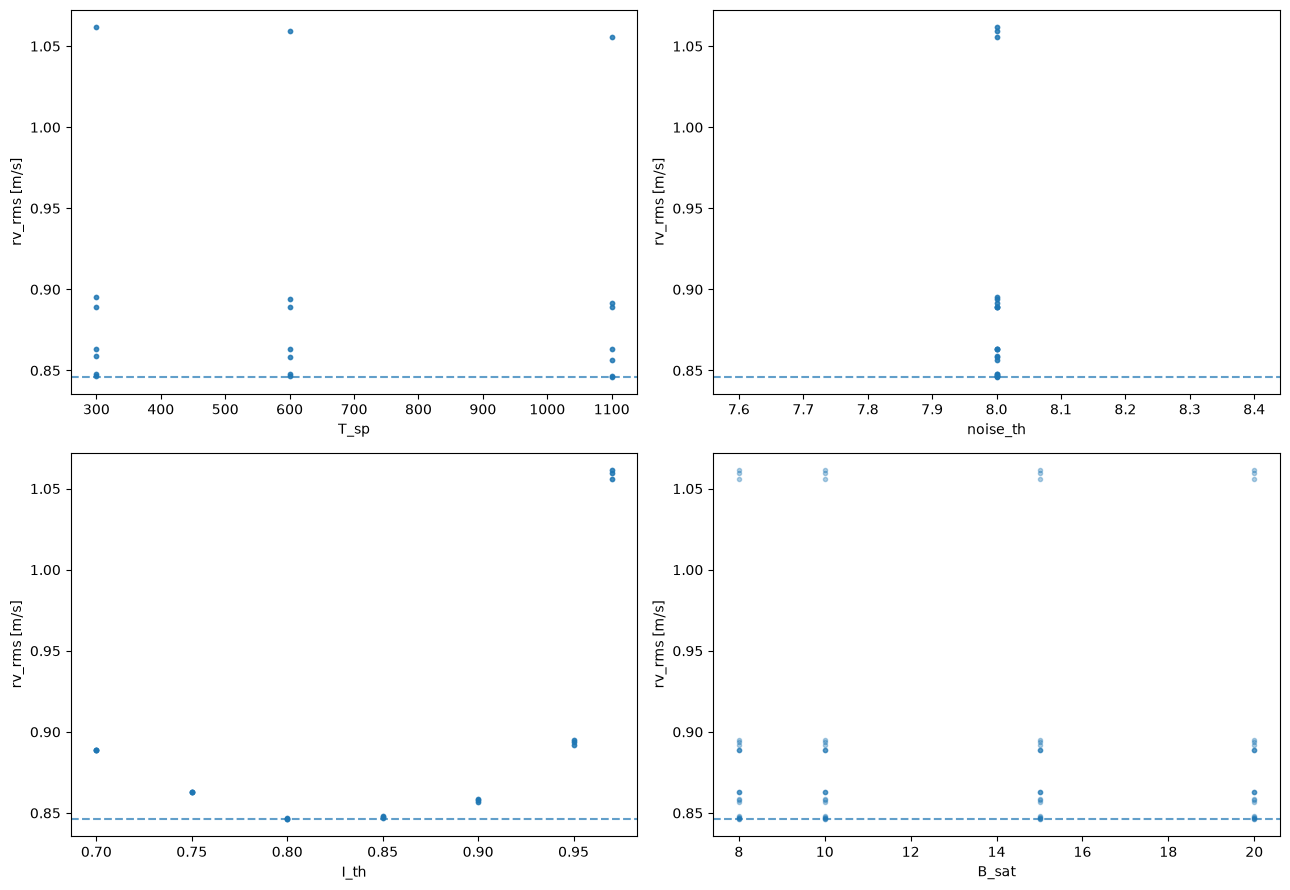

In [3]:
for noise in sorted(df['noise_th'].unique()):
    obs.plot_sweep_heatmaps(df, 'rv_rms', 'B_sat', 'I_th', 'T_sp', fixed={'noise_th': noise}, levels=[0.85, 0.90, 0.95],
                            unit='m/s', title='RV - HARPS-N (noise_th = %g)' % noise)
    for ax in plt.gcf().axes:
        for im in ax.images:
            im.set_clim(0.8141, 1)
    plt.show()
    
    obs.plot_sweep_heatmaps(df, 'rv_rms', 'B_sat', 'I_th', 'T_sp', fixed={'noise_th': noise},
                            unit='m/s', title='RV - HARPS-N (noise_th = %g)' % noise)
    plt.show()
    obs.plot_sweep_heatmaps(df, 'rv_rms', 'T_sp', 'I_th', 'B_sat', fixed={'noise_th': noise}, unit='m/s',
                            title='RV - HARPS-N (noise_th = %g)' % noise)
    plt.show()
obs.plot_sweep_parameters(df, 'rv_rms', unit='m/s')
plt.show()

## TSI against SORCE/TIM and TSIS-1

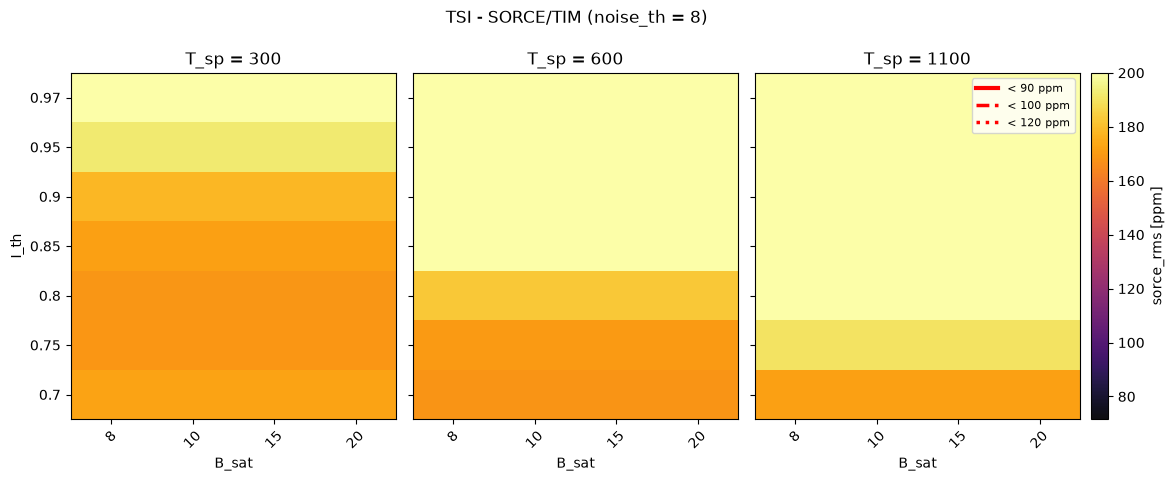

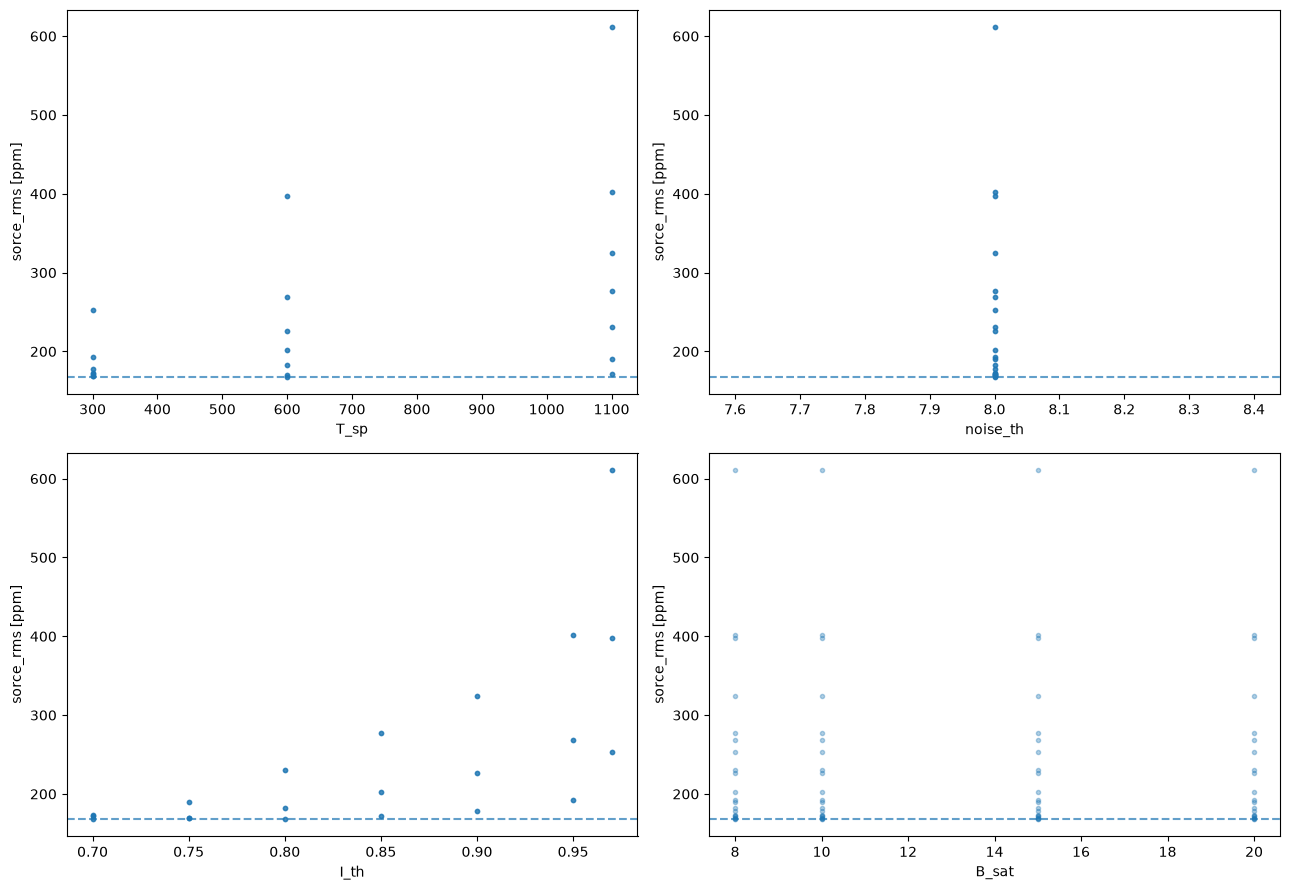

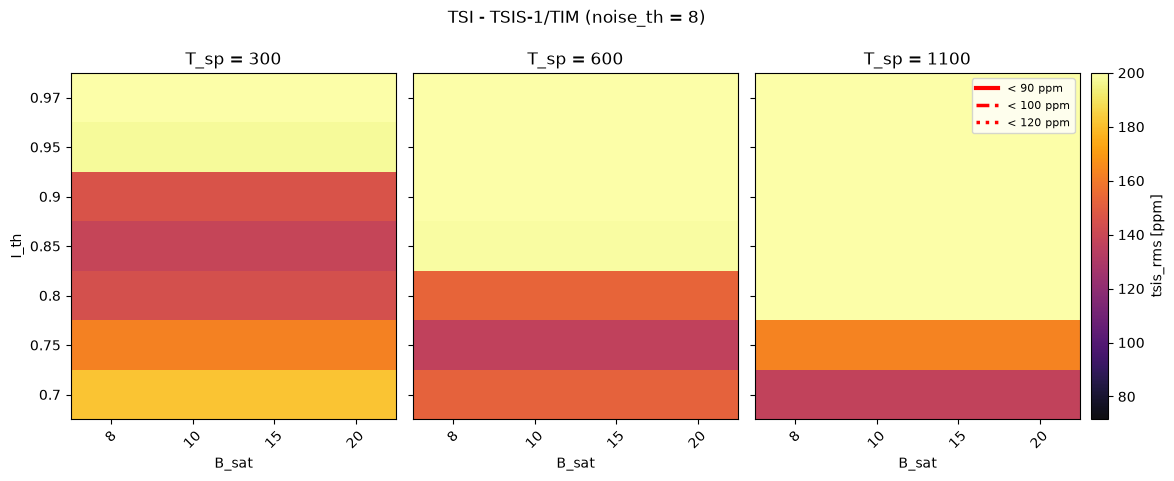

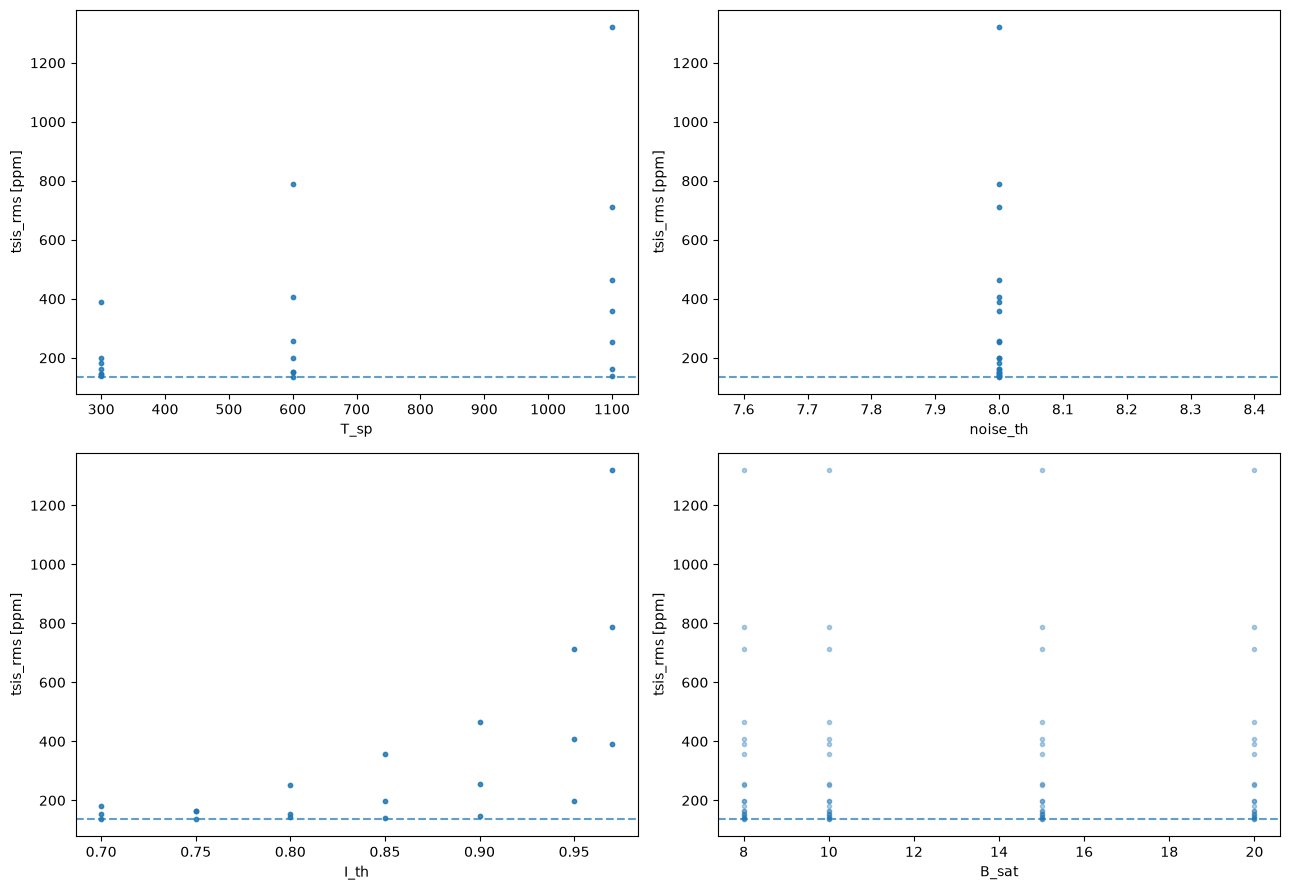

In [4]:
for value, title in (('sorce_rms', 'TSI - SORCE/TIM'), ('tsis_rms', 'TSI - TSIS-1/TIM')):
    if value not in df or df[value].isna().all():
        continue
    for noise in sorted(df['noise_th'].unique()):
        obs.plot_sweep_heatmaps(df, value, 'B_sat', 'I_th', 'T_sp', fixed={'noise_th': noise}, levels=[90, 100, 120],
                                unit='ppm', title='%s (noise_th = %g)' % (title, noise))
        for ax in plt.gcf().axes:
            for im in ax.images:
                im.set_clim(71.55, 200)
        plt.show()
    obs.plot_sweep_parameters(df, value, unit='ppm')
    plt.show()

In [5]:
import os
import matplotlib.dates as mdates
from matplotlib.collections import LineCollection

if not RECOMPUTE:                                # (already loaded by the recomputation)
    harps = obs.load_harpsn(local_path('harpsn_sun'), START)
    sorce, tsis = obs.load_sorce(local_path('sorce_tsi'), START), obs.load_tsis(local_path('tsis_tsi'), START)
    cuts = obs.load_interventions(local_path('harpsn_interventions'), START)


def set_folder(name):
    for f in (os.path.join(str(BASE), name), os.path.join(str(BASE), 'sets', name)):
        if os.path.isdir(f):
            return f
    raise FileNotFoundError('set %s not under %s' % (name, BASE))


def compare_set(name, max_ff_fc=20.0, max_ff_sp=5.0):
    """RV against HARPS-N and light curve against SORCE and TSIS of one set, on the epochs of obs.sweep_stats."""
    s = obs._read_series(set_folder(name))
    keep = ~((s['ff_fc'] > max_ff_fc) | (s['ff_sp'] > max_ff_sp))
    if WINDOW is not None:
        t0, t1 = (obs.jd_of_date(w) - obs.jd_of_date(START) for w in WINDOW)
        keep &= (s['time'] >= t0) & (s['time'] < t1 + 1)
    t, lc = s['time'][keep], s['lc'][keep]
    return {'t': t, 'lc': 1e6 * (lc / np.nanmean(lc) - 1),          # [ppm] around the mean of the whole simulation
            'rv': obs.compare_rv(harps, t, s['rv'][keep], interventions=cuts),
            'sorce': obs.compare_photometry(sorce, t, lc), 'tsis': obs.compare_photometry(tsis, t, lc)}


cmp = {}                                         # folder -> compare_set (the cells below only plot)
for k, name in enumerate(df['folder']):
    cmp[name] = compare_set(name)
    if (k + 1) % 100 == 0:
        print(k + 1, '/', len(df))
print(len(cmp), 'sets compared')

84 sets compared


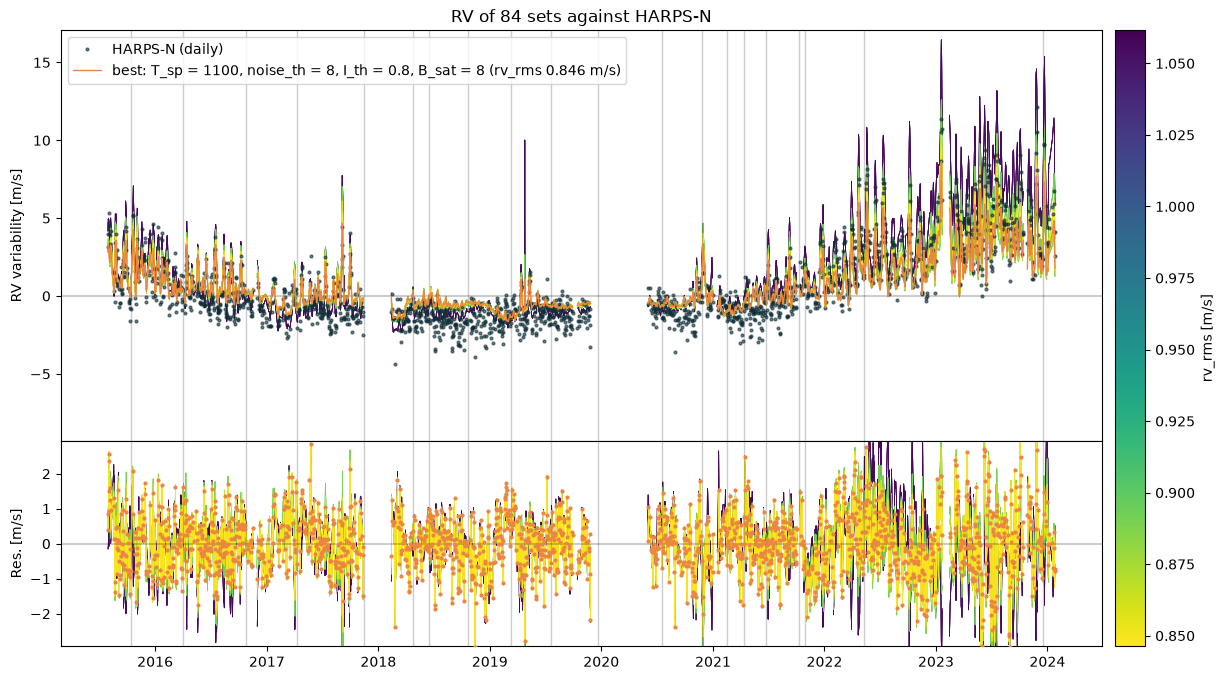

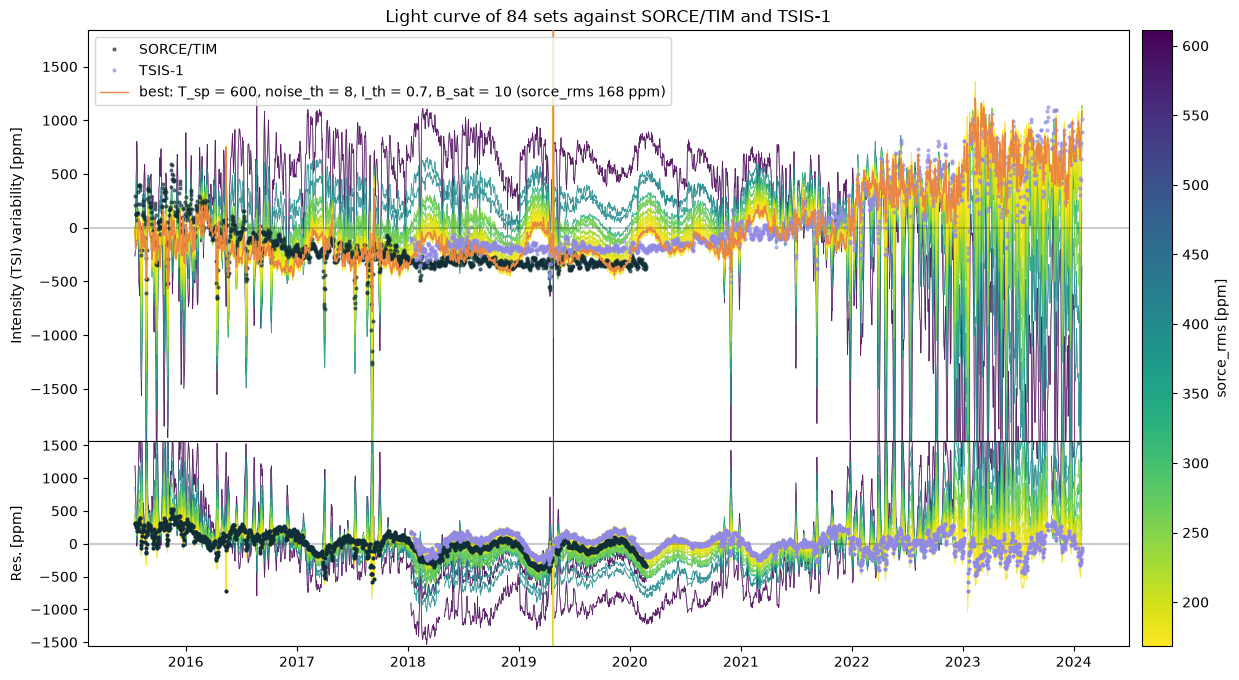

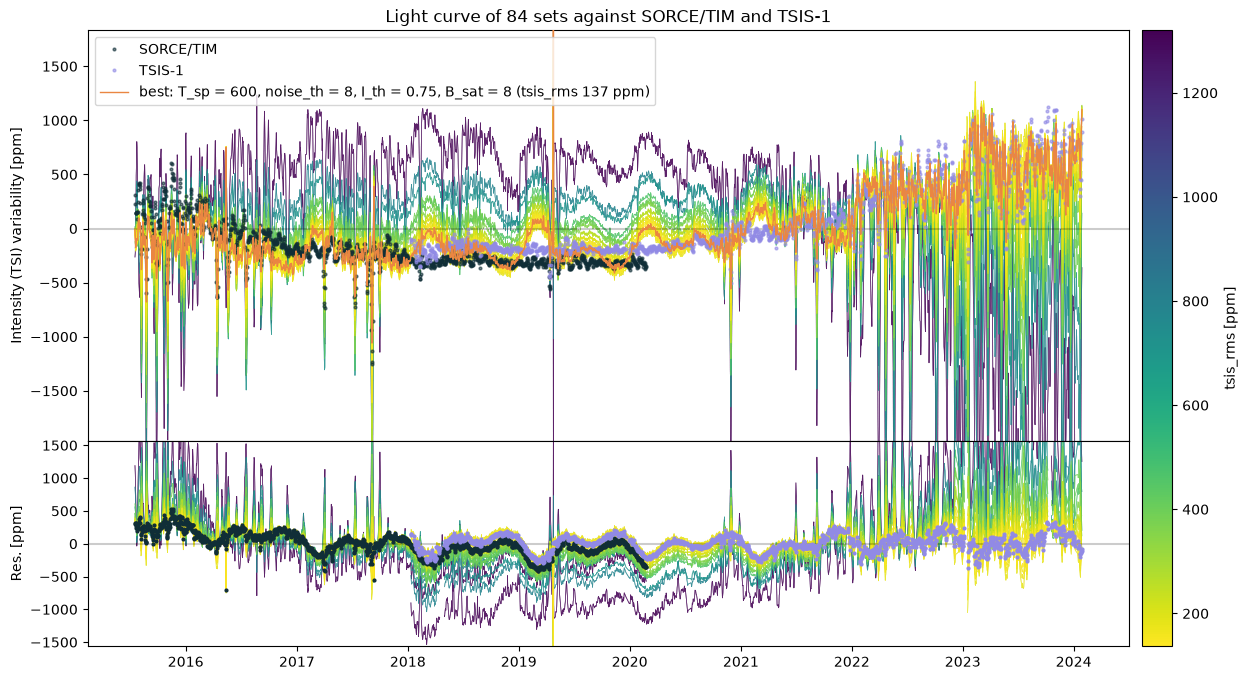

In [6]:
N_BEST = None                                    # e.g. 50: only the 50 best sets of the value of the colour
CMAP = plt.get_cmap('viridis_r')                 # small RMS (good) in yellow


def days_to_num(t):
    return mdates.date2num(np.datetime64(START)) + np.asarray(t, dtype=np.float64)


def broken(t, y, gap=10):
    """x (dates) and y with a NaN in the gaps longer than gap days, so that the lines are not drawn across them."""
    t, y = np.asarray(t, dtype=np.float64), np.asarray(y, dtype=np.float64)
    i = np.where(np.diff(t) > gap)[0] + 1
    return days_to_num(np.insert(t, i, np.nan)), np.insert(y, i, np.nan)


def sets_of(value):
    d = df.dropna(subset=[value]).sort_values(value, ascending=False)   # the best set last (drawn on top)
    return d if N_BEST is None else d.tail(N_BEST)


def draw_sets(ax, series, values, norm):
    ax.add_collection(LineCollection([np.column_stack(broken(t, y)) for t, y in series],
                                     colors=CMAP(norm(np.asarray(values))), linewidths=0.5, alpha=0.4))
    ax.autoscale_view()


def best_label(b, value, unit):
    return 'best: T_sp = %g, noise_th = %g, I_th = %g, B_sat = %g (%s %.3g %s)' \
        % (b['T_sp'], b['noise_th'], b['I_th'], b['B_sat'], value, b[value], unit)


def figure(d, value, unit):
    fig, (ax, ax_res) = plt.subplots(2, 1, sharex=True, figsize=(16, 8),
                                     gridspec_kw={'hspace': 0, 'height_ratios': [2, 1]})
    norm = plt.Normalize(d[value].min(), d[value].max())
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=CMAP), ax=[ax, ax_res], pad=0.01,
                 label='%s [%s]' % (value, unit))
    loc = mdates.AutoDateLocator()
    ax_res.xaxis.set_major_locator(loc)
    ax_res.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
    return fig, ax, ax_res, norm


def set_ylims(ax, ax_res, y_obs, res):
    lo, hi = np.nanmin(y_obs), np.nanmax(y_obs)          # the scale of the observations (bad sets can go far out)
    ax.set_ylim(lo - 0.3 * (hi - lo), hi + 0.3 * (hi - lo))
    lim = np.nanpercentile(np.abs(np.concatenate(res)), 99)
    ax_res.set_ylim(-1.1 * lim, 1.1 * lim)


def plot_all_rv(value='rv_rms'):
    d = sets_of(value)
    fig, ax, ax_res, norm = figure(d, value, 'm/s')
    r = [cmp[f]['rv'] for f in d['folder']]
    draw_sets(ax, [(x['t'], x['sim']) for x in r], d[value], norm)
    draw_sets(ax_res, [(x['t'], x['res']) for x in r], d[value], norm)
    best = r[-1]
    ax.plot(days_to_num(best['t']), best['obs'], 'o', ms=2, color=obs.COLOURS['harpsn'], alpha=0.6,
            label='HARPS-N (daily)', zorder=3)
    ax.plot(*broken(best['t'], best['sim']), '-', lw=1, color=obs.COLOURS['sim'],
            label=best_label(d.iloc[-1], value, 'm/s'), zorder=4)
    ax_res.plot(days_to_num(best['t']), best['res'], 'o', ms=2, color=obs.COLOURS['sim'], zorder=4)
    for a in (ax, ax_res):
        a.axhline(0, color='k', alpha=0.2)
        for c in best['interventions']:
            a.axvline(days_to_num(c), color='k', alpha=0.2, lw=1)
    set_ylims(ax, ax_res, best['obs'], [x['res'] for x in r])
    ax.set_ylabel('RV variability [m/s]')
    ax_res.set_ylabel('Res. [m/s]')
    ax.legend(loc='upper left')
    ax.set_title('RV of %d sets against HARPS-N' % len(d))
    return fig


def plot_all_tsi(value='sorce_rms'):
    d = sets_of(value)
    fig, ax, ax_res, norm = figure(d, value, 'ppm')
    c = [cmp[f] for f in d['folder']]
    draw_sets(ax, [(x['t'], x['lc']) for x in c], d[value], norm)
    for inst in ('sorce', 'tsis'):
        draw_sets(ax_res, [(x[inst]['t'], x[inst]['res']) for x in c], d[value], norm)
    best = c[-1]
    y_obs = []
    for inst in ('sorce', 'tsis'):
        ph = best[inst]
        if ph['n']:
            ax.plot(days_to_num(ph['t']), ph['obs'] + ph['offset'], 'o', ms=2, color=obs.COLOURS[inst], alpha=0.6,
                    label=ph['name'], zorder=3)
            ax_res.plot(days_to_num(ph['t']), ph['res'], 'o', ms=2, color=obs.COLOURS[inst], zorder=4)
            y_obs.append(ph['obs'] + ph['offset'])
    ax.plot(*broken(best['t'], best['lc']), '-', lw=1, color=obs.COLOURS['sim'],
            label=best_label(d.iloc[-1], value, 'ppm'), zorder=4)
    for a in (ax, ax_res):
        a.axhline(0, color='k', alpha=0.2)
    set_ylims(ax, ax_res, np.concatenate(y_obs), [x[i]['res'] for x in c for i in ('sorce', 'tsis')])
    ax.set_ylabel('Intensity (TSI) variability [ppm]')
    ax_res.set_ylabel('Res. [ppm]')
    ax.legend(loc='upper left')
    ax.set_title('Light curve of %d sets against SORCE/TIM and TSIS-1' % len(d))
    return fig


plot_all_rv('rv_rms')
plt.show()
for value in ('sorce_rms', 'tsis_rms'):
    if value in df and df[value].notna().any():
        plot_all_tsi(value)
        plt.show()

best rv_rms: T_sp = 1100, noise_th = 8, I_th = 0.8, B_sat = 20 (rv_rms 0.846 m/s)
SORCE/TIM  1638 days  residuals: MAD   132.5 ppm  RMS   230.8 ppm   (observed: MAD    71.1  RMS   196.3 ppm)
TSIS-1     1873 days  residuals: MAD   123.8 ppm  RMS   253.2 ppm   (observed: MAD   114.5  RMS   343.0 ppm)


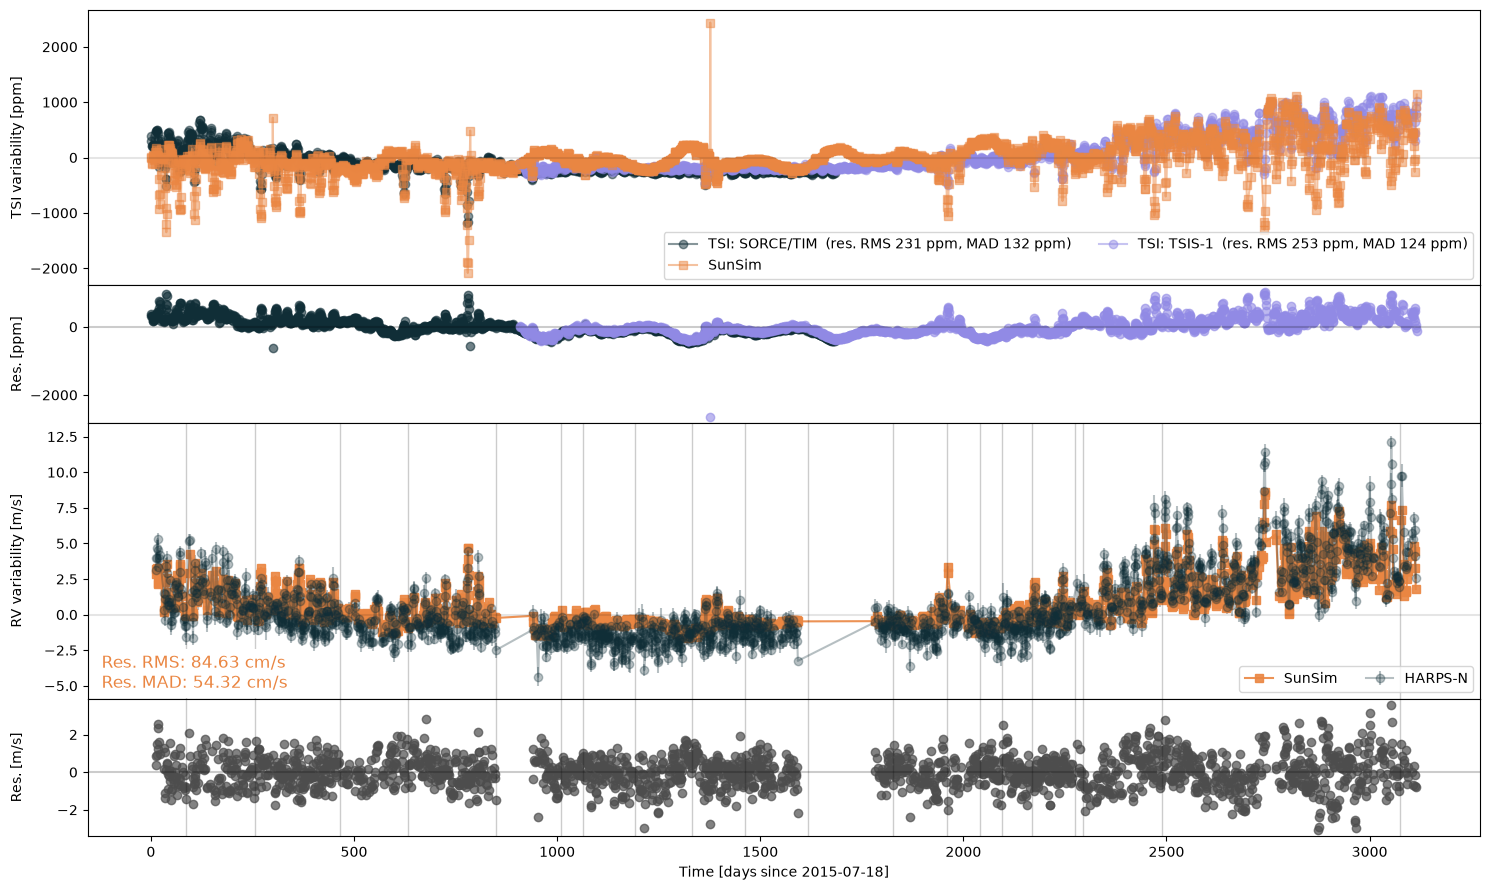

best sorce_rms: T_sp = 600, noise_th = 8, I_th = 0.7, B_sat = 10 (sorce_rms 168 ppm)
SORCE/TIM  1638 days  residuals: MAD    95.7 ppm  RMS   168.2 ppm   (observed: MAD    71.1  RMS   196.3 ppm)
TSIS-1     1873 days  residuals: MAD    91.8 ppm  RMS   152.1 ppm   (observed: MAD   114.5  RMS   343.0 ppm)


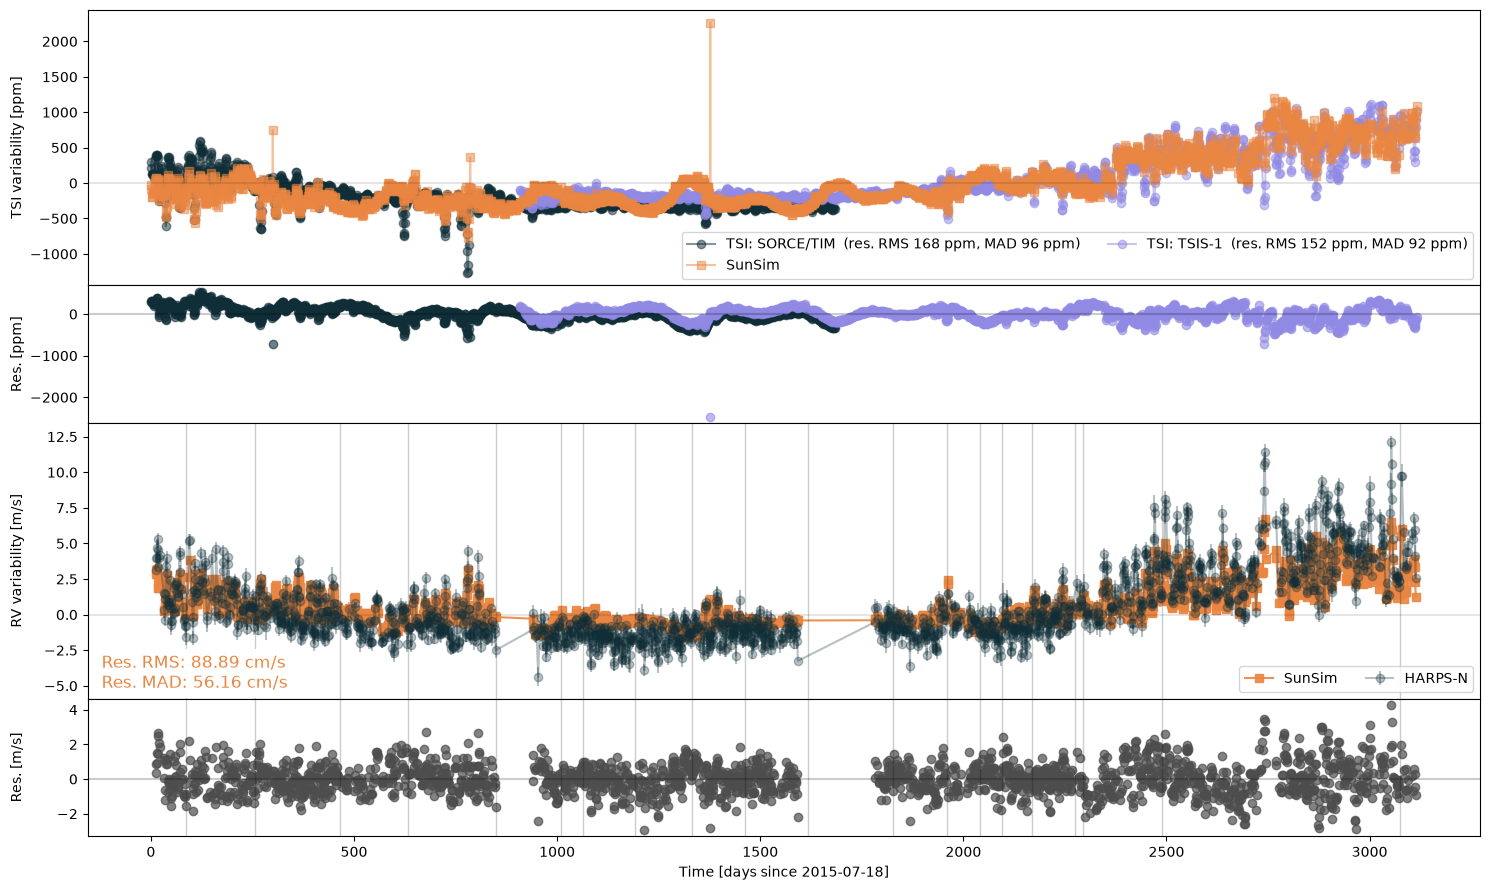

best tsis_rms: T_sp = 600, noise_th = 8, I_th = 0.75, B_sat = 10 (tsis_rms 137 ppm)
SORCE/TIM  1638 days  residuals: MAD   101.8 ppm  RMS   170.0 ppm   (observed: MAD    71.1  RMS   196.3 ppm)
TSIS-1     1873 days  residuals: MAD    82.0 ppm  RMS   136.7 ppm   (observed: MAD   114.5  RMS   343.0 ppm)


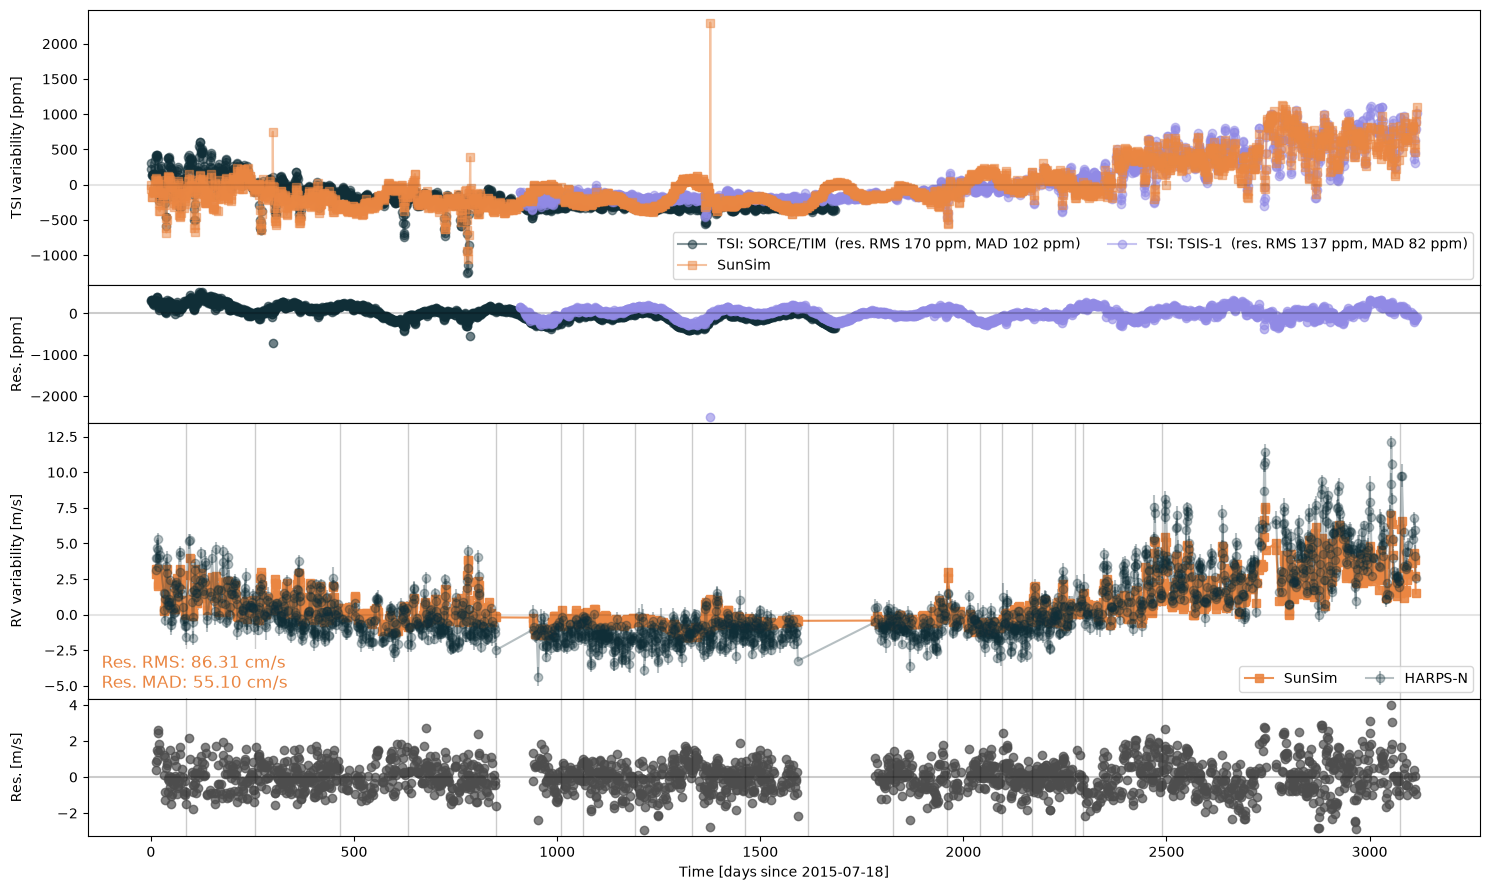

In [7]:
# the best set of every statistic in detail (TSI and RV with their residuals)
for value in ('rv_rms', 'sorce_rms', 'tsis_rms'):
    if value not in df or df[value].isna().all():
        continue
    b = obs.best_sets(df, value, 1).iloc[0]
    c = cmp[b['folder']]
    print(best_label(b, value, 'm/s' if value.startswith('rv') else 'ppm').replace('best', 'best ' + value))
    obs.print_summary([c['sorce'], c['tsis']])
    obs.plot_comparison([c['sorce'], c['tsis']], c['rv'], start=START)
    plt.show()